# Static Malware Detection: PE Forensics, Model Evaluation, TreeSHAP & SOC Decisions

### École Nationale Supérieure d'intelligence Artificielle et Sciences des Données - Ibn Zohr University

**Master:** Intelligent Systems Security and Cyber Defense | **Module M115:** AI & Intelligent Systems

**Developed by:** Zakaria TAIRARI | **Instructor:** Prof. Sara EL-ATEIF | **Academic Year:** 2026–2027

---
## Introduction

This practical work explores the application of supervised machine learning to cybersecurity, focusing on the static detection of Windows PE malware through classification models.

The study relies on a synthetic, EMBER-inspired dataset representing PE files, described by static features extracted from their executable structure and characteristics. The objective is to investigate the dataset, develop and compare different classification algorithms, evaluate their performance, and interpret their predictions using TreeSHAP (SHapley Additive exPlanations).

Particular attention is given to feature forensics, data leakage, model generalization, and decision thresholds under different SOC operational costs. The study also examines model disagreements, false positive and false negative trade-offs, and the operational feasibility of deploying such a detection system in an analyst-assisted environment.

- Github: #
- Kaggle: #

## Case Context – AtlasPay Services

The practical work is conducted within the context of AtlasPay Services, a fictional Moroccan payment-services company seeking to strengthen its cybersecurity capabilities through ML-based malware detection.

The company's Security Operations Center (SOC) aims to introduce static analysis of Windows Portable Executable (PE) files to identify potentially malicious files before execution. The proposed system is intended to support the initial triage process by analyzing extracted file features and generating alerts for further investigation by security analysts.

The operational scenario assumes approximately 12,000 PE files processed daily, with a team of six SOC analysts and a planning target of no more than 120 model-generated alerts per day. These constraints introduce practical considerations beyond classification performance, particularly alert volume, false positive and false negative costs, inference latency, and analyst workload.

The initial objective is to develop an analyst-assisted detection system rather than an autonomous blocking mechanism. Any future transition toward automated blocking would require additional validation, representative production data, and careful assessment of the associated operational risks.

**Important source boundary:** The notebook uses a deterministic EMBER-inspired synthetic dataset of 6,000 PE-file records, it is not the real EMBER benchmark, and not evidence of production detection performance. the objective is to determine what can and cannot be concluded from this experiment.

## Engineering mission

You are the applied ML team asked to deliver a defensible recommendation to AtlasPay’s CISO. You must investigate the data, design the evaluation, compare model families, examine errors, and select a model and operating threshold under explicit operational constraints.

You will complete 5 engineering phases:

1. **Forensic Data Understanding & Trap Detection**
2. **Leakage-Free Preprocessing & 5-Fold Cross-Validation**
3. **Multi-Algorithm Head-to-Head Benchmark**
4. **Error Forensics & TreeSHAP Explainability**
5. **SOC Cost Matrix & Threshold Optimization**

**Core question:** *Which model should AtlasPay deploy first, for which operational role, and what evidence would justify trusting it?*

## Environment and dataset
Import the packages, and generate the EMBER inspired dataset.

In [126]:
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve)
from sklearn.base import clone
from lightgbm import LGBMClassifier
import shap

SEED = 42
rng = np.random.default_rng(SEED)

In [96]:
def load_ember_forensic_dataset(n_samples=6000, seed=42):
    rng = np.random.default_rng(seed)
    y = rng.binomial(1, 0.25, n_samples)
    is_mal = y == 1
    archetype_b = is_mal & (rng.random(n_samples) < 0.35)
    archetype_a = is_mal & (~archetype_b)

    max_entropy = np.where(archetype_a, rng.normal(7.35, .40, n_samples),
                  np.where(archetype_b, rng.normal(4.30, .55, n_samples),
                           rng.normal(5.50, .95, n_samples))).clip(1, 7.99)
    import_count = np.where(archetype_a, rng.normal(14, 7, n_samples),
                   np.where(archetype_b, rng.normal(115, 35, n_samples),
                            rng.normal(95, 45, n_samples))).clip(0, 500).astype(float)
    suspicious_apis = np.where(archetype_a, rng.poisson(3.0, n_samples),
                      np.where(archetype_b, rng.poisson(11.5, n_samples),
                               rng.poisson(1.8, n_samples)))
    has_valid_sig = np.where(archetype_a, rng.binomial(1,.03,n_samples),
                    np.where(archetype_b, rng.binomial(1,.55,n_samples),
                             rng.binomial(1,.78,n_samples)))
    has_rwx = np.where(is_mal, rng.binomial(1,.52,n_samples), rng.binomial(1,.04,n_samples))
    vsize = np.where(archetype_a, rng.uniform(1.8,6.5,n_samples),
                     rng.normal(1.08,.22,n_samples)).clip(.2,15)
    res_entropy = np.where(is_mal, rng.normal(6.2,1.3,n_samples),
                           rng.normal(4.0,1.2,n_samples)).clip(0,7.99)
    urls = np.where(is_mal, rng.poisson(4.2,n_samples), rng.poisson(.6,n_samples))
    bad_time = np.where(is_mal, rng.binomial(1,.38,n_samples), rng.binomial(1,.03,n_samples))
    sections = np.where(is_mal, rng.integers(1,11,n_samples), rng.integers(3,7,n_samples))
    tls = np.where(is_mal, rng.binomial(1,.26,n_samples), rng.binomial(1,.02,n_samples))
    exports = np.where(is_mal, rng.poisson(1.0,n_samples), rng.poisson(7.5,n_samples))
    flip = rng.random(n_samples) < .04
    y_final = np.where(flip, 1-y, y)
    vt = np.where(y_final==1, rng.integers(18,68,n_samples), rng.integers(0,3,n_samples))
    df = pd.DataFrame({
      "SHA256_File_ID":[f"sha256_{i:05d}_pe" for i in range(n_samples)],
      "Max_Section_Entropy":max_entropy, "Import_Count":import_count,
      "Suspicious_API_Imports":suspicious_apis, "Has_Valid_Signature":has_valid_sig,
      "Has_RWX_Section":has_rwx, "Virtual_to_Raw_Size_Ratio":vsize,
      "Resource_Entropy":res_entropy, "Num_Embedded_URLs_IPs":urls,
      "Abnormal_Compile_Timestamp":bad_time, "Num_Sections":sections,
      "Has_TLS_Callback":tls, "Export_Count":exports,
      "VT_PostScan_Detections":vt, "Is_Malware":y_final
    })
    df.loc[rng.random(n_samples)<.05, "Resource_Entropy"] = np.nan
    df.loc[rng.random(n_samples)<.04, "Import_Count"] = np.nan
    df.loc[rng.random(n_samples)<.01, "Virtual_to_Raw_Size_Ratio"] = 99999.0
    return df
df = load_ember_forensic_dataset()
print(df.shape, "Malware prevalence:", round(df.Is_Malware.mean(),3))
display(df.head())

(6000, 15) Malware prevalence: 0.268


,SHA256_File_ID,Max_Section_Entropy,Import_Count,Suspicious_API_Imports,Has_Valid_Signature,Has_RWX_Section,Virtual_to_Raw_Size_Ratio,Resource_Entropy,Num_Embedded_URLs_IPs,Abnormal_Compile_Timestamp,Num_Sections,Has_TLS_Callback,Export_Count,VT_PostScan_Detections,Is_Malware
0,sha256_00000_pe,7.461459,25.464072,2,0,1,5.158277,7.081268,3,0,2,0,2,45,1
1,sha256_00001_pe,5.872605,104.603878,2,1,0,0.871620,4.123092,0,0,4,0,6,2,0
2,sha256_00002_pe,7.188000,13.758941,4,0,1,3.447490,4.776004,2,0,9,0,2,36,1
3,sha256_00003_pe,6.330688,96.169063,2,1,0,1.027833,4.654296,3,0,4,0,8,0,0
4,sha256_00004_pe,5.211025,97.108682,3,0,0,1.031020,4.442302,0,0,5,0,2,1,0


## 1. Forensic data audit and problem formulation
The target is `Is_Malware` (`1 = malware`, `0 = benign`). At deployment time, the detector must only use information available when the PE file is first inspected.

### 1.1 Report dataset dimensions, class balance, missing values, duplicates and summary statistics

In [97]:
df.shape

(6000, 15)

In [98]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   SHA256_File_ID              6000 non-null   str    
 1   Max_Section_Entropy         6000 non-null   float64
 2   Import_Count                5771 non-null   float64
 3   Suspicious_API_Imports      6000 non-null   int64  
 4   Has_Valid_Signature         6000 non-null   int64  
 5   Has_RWX_Section             6000 non-null   int64  
 6   Virtual_to_Raw_Size_Ratio   6000 non-null   float64
 7   Resource_Entropy            5711 non-null   float64
 8   Num_Embedded_URLs_IPs       6000 non-null   int64  
 9   Abnormal_Compile_Timestamp  6000 non-null   int64  
 10  Num_Sections                6000 non-null   int64  
 11  Has_TLS_Callback            6000 non-null   int64  
 12  Export_Count                6000 non-null   int64  
 13  VT_PostScan_Detections      6000 non-null   

In [99]:
# Missing values
df.isna().sum()

SHA256_File_ID                  0
Max_Section_Entropy             0
Import_Count                  229
Suspicious_API_Imports          0
Has_Valid_Signature             0
Has_RWX_Section                 0
Virtual_to_Raw_Size_Ratio       0
Resource_Entropy              289
Num_Embedded_URLs_IPs           0
Abnormal_Compile_Timestamp      0
Num_Sections                    0
Has_TLS_Callback                0
Export_Count                    0
VT_PostScan_Detections          0
Is_Malware                      0
dtype: int64

In [100]:
# Duplicate rows
df.duplicated().sum()

np.int64(0)

In [101]:
df.describe()

,Max_Section_Entropy,Import_Count,Suspicious_API_Imports,Has_Valid_Signature,Has_RWX_Section,Virtual_to_Raw_Size_Ratio,Resource_Entropy,Num_Embedded_URLs_IPs,Abnormal_Compile_Timestamp,Num_Sections,Has_TLS_Callback,Export_Count,VT_PostScan_Detections,Is_Malware
count,6000.000000,5771.000000,6000.000000,6000.000000,6000.000000,6000.000000,5711.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000
mean,5.709010,83.386866,2.800167,0.630833,0.149833,984.890348,4.535160,1.468333,0.114833,4.758667,0.079167,5.907500,12.080833,0.268500
std,1.170152,50.301130,3.094430,0.482619,0.356938,9868.008483,1.501097,1.951742,0.318847,1.784551,0.270021,3.708401,19.753109,0.443216
min,2.146111,0.000000,0.000000,0.000000,0.000000,0.367195,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,4.821742,41.184528,1.000000,0.000000,0.000000,0.955570,3.483114,0.000000,0.000000,3.000000,0.000000,3.000000,0.000000,0.000000
50%,5.639862,85.663796,2.000000,1.000000,0.000000,1.129836,4.432941,1.000000,0.000000,5.000000,0.000000,6.000000,2.000000,0.000000
75%,6.604762,120.408591,3.000000,1.000000,0.000000,1.366755,5.517712,2.000000,0.000000,6.000000,0.000000,9.000000,21.000000,1.000000
max,7.990000,320.325585,24.000000,1.000000,1.000000,99999.000000,7.990000,11.000000,1.000000,10.000000,1.000000,18.000000,67.000000,1.000000


In [102]:
# Class balance
is_malware = df['Is_Malware']
is_malware.value_counts(normalize=True)

Is_Malware
0    0.7315
1    0.2685
Name: proportion, dtype: float64

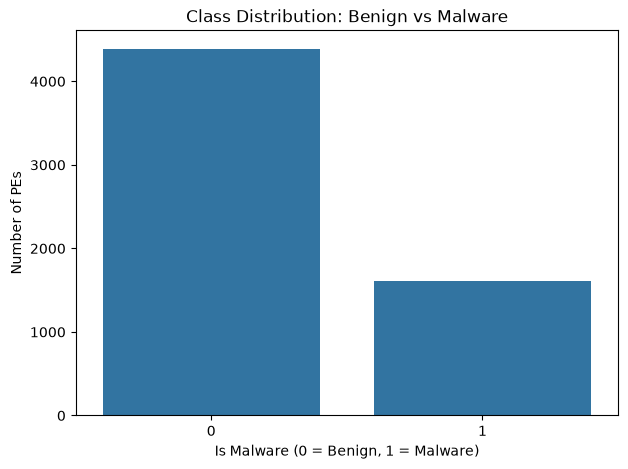

In [103]:
plt.figure(figsize=(7, 5))

sns.countplot(x=is_malware)

plt.title('Class Distribution: Benign vs Malware')
plt.xlabel('Is Malware (0 = Benign, 1 = Malware)')
plt.ylabel('Number of PEs')

plt.show()

### 1.2 Exclude the identifier and the post-scan field
Two columns must be excluded from the predictive feature set:

1. `SHA256_File_ID` is an identifier, not a meaningful behavioral or structural feature.
2. `VT_PostScan_Detections` represents information obtained after the analysis process, including it would introduce target leakage, allowing the model to exploit information that would not be available at the intended prediction time.

In [104]:
df = df.drop(columns=[
    "SHA256_File_ID",
    "VT_PostScan_Detections",
])

### 1.3 Inspect the suspicious ratio values and feature distributions

In [ ]:
feature = "Virtual_to_Raw_Size_Ratio"

print(df[feature].describe())

# Inspect suspicious observations
print("Occurrences of 99999:", (df[feature] == 99999.0).sum())

count     6000.000000
mean       984.890348
std       9868.008483
min          0.367195
25%          0.955570
50%          1.129836
75%          1.366755
max      99999.000000
Name: Virtual_to_Raw_Size_Ratio, dtype: float64
Occurrences of 99999: 59


**Recommended treatment:**

I recommend replacing 99999.0 with NaN rather than treating it as an actual numerical measurement. The sentinel does not represent a meaningful feature value. Keeping it would introduce an artificial extreme into the distribution, potentially distorting statistical summaries, scaling and model training.

In [106]:
df[feature] = df[feature].replace(99999.0, np.nan)

### 1.4 Visualize `Max_Section_Entropy` vs `Suspicious_API_Imports`

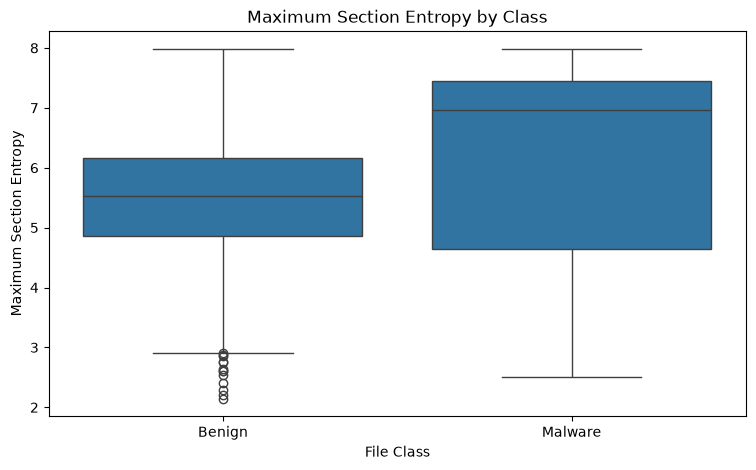

In [107]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x=is_malware,
    y="Max_Section_Entropy"
)

plt.xticks([0, 1], ["Benign", "Malware"])
plt.title("Maximum Section Entropy by Class")
plt.xlabel("File Class")
plt.ylabel("Maximum Section Entropy")

plt.show()

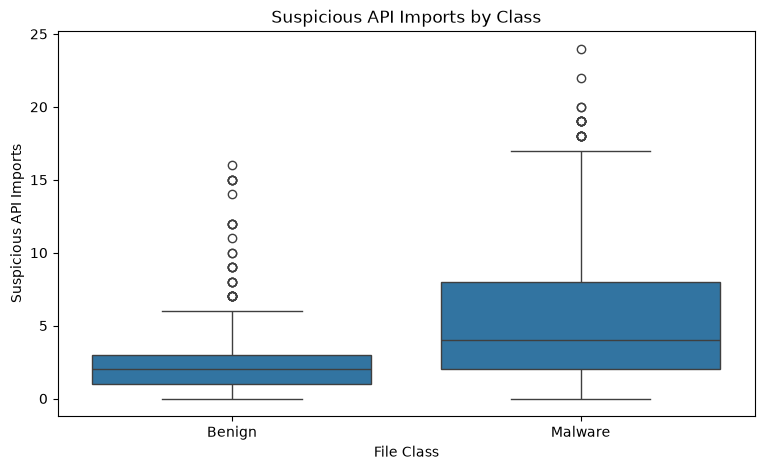

In [108]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Is_Malware",
    y="Suspicious_API_Imports"
)

plt.xticks([0, 1], ["Benign", "Malware"])
plt.title("Suspicious API Imports by Class")
plt.xlabel("File Class")
plt.ylabel("Suspicious API Imports")

plt.show()

### 1.5 Define the target and clean feature matrix

In [109]:
X = df.drop(columns="Is_Malware")
y = is_malware
X.index.equals(y.index)

True

## 2. Leakage-safe evaluation protocol
Use a stratified 80/20 development/test split. The test set is a lockbox and must not be used for model selection or threshold tuning.

Within the development set, compare models using 5-fold stratified cross-validation. All learned preprocessing (imputation and scaling) must be inside each pipeline so it is refitted separately in each training fold.

### 2.1 Create the train/test split

In [110]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)

### 2.2 Define a preprocessing pipeline with median imputation

In [111]:
def make_linear_pipeline(model):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", RobustScaler()),
        ("classifier", model)
    ])

def make_tree_pipeline(model):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", model)
    ])

Scaling is not needed for tree-based models because decision trees make decisions based on feature thresholds and ordering, not on distances or magnitudes.

### 2.3 Build candidate pipelines
#### Model 1: Logistic Regression

In [112]:
lr = make_linear_pipeline(
    LogisticRegression(
        max_iter=2000,
        random_state=SEED
    )
)

#### Model 2: Decision Tree

In [113]:
dt = make_tree_pipeline(
    DecisionTreeClassifier(random_state=SEED)
)

#### Model 3: Random Forest

In [114]:
rf = make_tree_pipeline(
    RandomForestClassifier(
        n_estimators=200,
        random_state=SEED,
        n_jobs=-1
    )
)

#### Model 4: LightGBM

In [115]:
gb = make_tree_pipeline(
    LGBMClassifier(
        n_estimators=200,
        random_state=42,
        verbosity=-1
    )
)

### 2.4 Perform 5-fold stratified cross-validation
For Stacking, combine the predictions of the four base learners using a Logistic Regression meta-learner.

In [116]:
stacking = StackingClassifier(
    estimators=[
        ("lr", lr),
        ("dt", dt),
        ("rf", rf),
        ("gb", gb)
    ],
    final_estimator=LogisticRegression(max_iter=2000),
    cv=5,
    stack_method="predict_proba",
    n_jobs=1
)

In [ ]:
models = {
    "Logistic Regression": lr,
    "Decision Tree": dt,
    "Random Forest": rf,
    "LightGBM": gb,
    "Stacking": stacking
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

results = []

for name, model in models.items():

    train_f1_scores = []
    val_f1_scores = []
    val_pr_auc_scores = []
    fit_times = []

    for train_idx, val_idx in cv.split(X_train, y_train):

        X_train_fold = X_train.iloc[train_idx]
        X_val_fold = X_train.iloc[val_idx]

        y_train_fold = y_train.iloc[train_idx]
        y_val_fold = y_train.iloc[val_idx]

        start = time.perf_counter()

        model.fit(X_train_fold, y_train_fold)

        fit_times.append(time.perf_counter() - start)

        # Training performance
        y_train_pred = model.predict(X_train_fold)

        train_f1_scores.append(
            f1_score(y_train_fold, y_train_pred)
        )

        # Validation performance
        y_val_pred = model.predict(X_val_fold)

        val_f1_scores.append(
            f1_score(y_val_fold, y_val_pred)
        )

        # Validation PR-AUC
        y_val_proba = model.predict_proba(X_val_fold)[:, 1]

        val_pr_auc_scores.append(
            average_precision_score(y_val_fold, y_val_proba)
        )

    train_f1 = np.mean(train_f1_scores)
    val_f1 = np.mean(val_f1_scores)

    results.append({
        "Model": name,
        "Train F1": train_f1,
        "Validation F1": val_f1,
        "Validation PR-AUC": np.mean(val_pr_auc_scores),
        "Fit Time (s)": np.mean(fit_times),
        "F1 Gap": train_f1 - val_f1
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Validation PR-AUC",
    ascending=False
).reset_index(drop=True)

display(results_df.round(5))

,Model,Train F1,Validation F1,Validation PR-AUC,Fit Time (s),F1 Gap
0,Stacking,0.98610,0.92443,0.91080,4.35230,0.06167
1,Logistic Regression,0.92312,0.92381,0.90799,0.02112,-0.00069
2,Random Forest,1.00000,0.92370,0.90489,0.55188,0.07630
3,LightGBM,1.00000,0.92141,0.90148,0.14929,0.07859
4,Decision Tree,1.00000,0.83011,0.73298,0.04330,0.16989


#### Decision checkpoint 1 — Select a shortlist
1. Which model shows the largest train–validation gap? What does it suggest?
    
    The model showing the largest train–validation gap is the Decision Tree. It achieves a training F1-score of 1.0, compared with a validation F1-score of 0.83011, resulting in a generalization gap of 0.16989. This indicates that the model fits the training observations substantially better than unseen validation observations, suggesting limited generalization.

2. Does the linear baseline already perform competitively?

    Yes, the linear baseline model performs very well with a training F1-score of 0.92312, compared with a validation F1-score of 0.92381, resulting in a negative generalization gap of -0.00069.

3. Does Random Forest improve on the single tree?

    Yes, although it's still showing signs of overfitting, the Random Forest performs better than the single tree.

4. Does boosting improve PR-AUC enough to justify its complexity?

    LightGBM's additional model complexity is not justified by these results. Logistic Regression provides better predictive performance, faster execution, and easier interpretability.

5. Is stacking justified by the measured gain, runtime and deployment context?

    Stacking is the best-performing model numerically, but its marginal improvement over Logistic Regression does not clearly justify its substantially higher computational cost and operational complexity.

### 2.5 Hardware and runtime limitations
**AtlasPay operating constraint:** the service receives about 12,000 PE files/day, while the 6-person SOC wants no more than 120 model-generated review alerts/day. Treat this as a queue-capacity constraint to test. Training time matters during model updates, inference latency matters during scanning. These are separate measurements.

**Shortlist:**
- **Logistic Regression** - efficient baseline.
- **Stacking** - best CV predictive performance.
- **LightGBM** - representative boosting model.

In [118]:
shortlisted = {
    "Logistic Regression": models["Logistic Regression"],
    "Stacking": models["Stacking"],
    "LightGBM": models["LightGBM"]
}

fitted_models = {}

for name, model in shortlisted.items():
    fitted_model = clone(model)
    fitted_model.fit(X_train, y_train)
    fitted_models[name] = fitted_model

                 Model  Mean Latency (ms / 1000 files)  Std (ms)  Median (ms)
0  Logistic Regression                        2.202268  0.253647     2.129283
1             LightGBM                       10.405654  3.790861     8.255477
2             Stacking                       78.414854  4.366780    80.831586


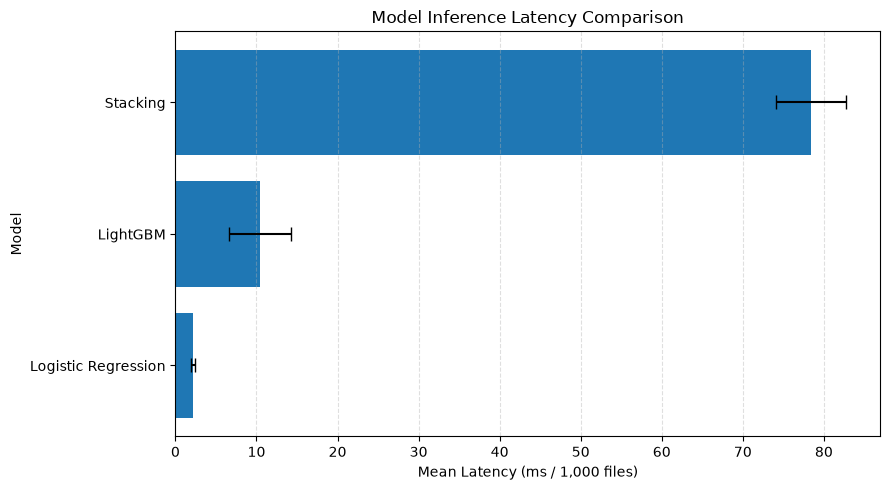

In [123]:
BATCH_SIZE = 1000
N_WARMUP = 5
N_REPEATS = 30

# Use 1,000 representative samples
X_batch = X_train.iloc[:BATCH_SIZE]

if len(X_batch) < BATCH_SIZE:
    raise ValueError("Not enough samples for a batch of 1,000 files.")

results = []

for name, model in fitted_models.items():

    # Warm-up
    for _ in range(N_WARMUP):
        model.predict(X_batch)

    # Repeated batch predictions
    times = []

    for _ in range(N_REPEATS):
        start = time.perf_counter()
        model.predict(X_batch)
        elapsed = time.perf_counter() - start

        times.append(elapsed * 1000)

    results.append({
        "Model": name,
        "Mean Latency (ms / 1000 files)": np.mean(times),
        "Std (ms)": np.std(times),
        "Median (ms)": np.median(times)
    })

latency_df = pd.DataFrame(results)

latency_df = latency_df.sort_values(
    "Mean Latency (ms / 1000 files)"
).reset_index(drop=True)

print(latency_df)

plt.figure(figsize=(9, 5))

plt.barh(
    latency_df["Model"],
    latency_df["Mean Latency (ms / 1000 files)"],
    xerr=latency_df["Std (ms)"],
    capsize=5
)

plt.xlabel("Mean Latency (ms / 1,000 files)")
plt.ylabel("Model")
plt.title("Model Inference Latency Comparison")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## 3. Error forensics and local explanation
The goal is to find a test observation where Logistic Regression and a tree-based model disagree, then use SHAP to understand what influenced the tree model's prediction.
We'll use Logistic Regression and LightGBM as the two candidates.

### 3.1 Find an observation where the models disagree
A disagreement occurs when one model predicts malware and the other predicts benign. Using classification threshold of 0.5 for both models initially.

In [124]:
# Select the two fitted models
lr_model = fitted_models["Logistic Regression"]
tree_model = fitted_models["LightGBM"]

THRESHOLD = 0.5

# Predicted probabilities for the positive class (malware = 1)
lr_proba = lr_model.predict_proba(X_test)[:, 1]
tree_proba = tree_model.predict_proba(X_test)[:, 1]

# Convert probabilities into binary predictions
lr_pred = (lr_proba >= THRESHOLD).astype(int)
tree_pred = (tree_proba >= THRESHOLD).astype(int)

# Find disagreements
disagreement_mask = lr_pred != tree_pred

disagreements = pd.DataFrame({
    "Original_Row_ID": X_test.index,
    "True_Label": np.asarray(y_test),
    "LR_Probability": lr_proba,
    "LR_Prediction": lr_pred,
    "LightGBM_Probability": tree_proba,
    "LightGBM_Prediction": tree_pred,
    "Threshold": THRESHOLD
}, index=X_test.index).loc[disagreement_mask]

disagreements

,Original_Row_ID,True_Label,LR_Probability,LR_Prediction,LightGBM_Probability,LightGBM_Prediction,Threshold
5763,5763,1,0.770682,1,0.359423,0,0.5
5115,5115,1,0.426465,0,0.995655,1,0.5
1945,1945,1,0.979368,1,0.352498,0,0.5
3013,3013,1,0.545910,1,0.031336,0,0.5


### 3.2 Generate the local TreeSHAP explanation

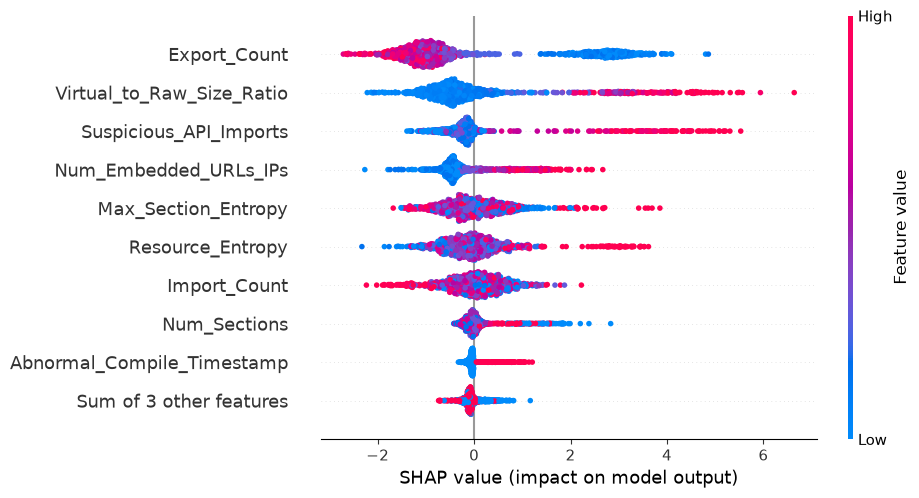

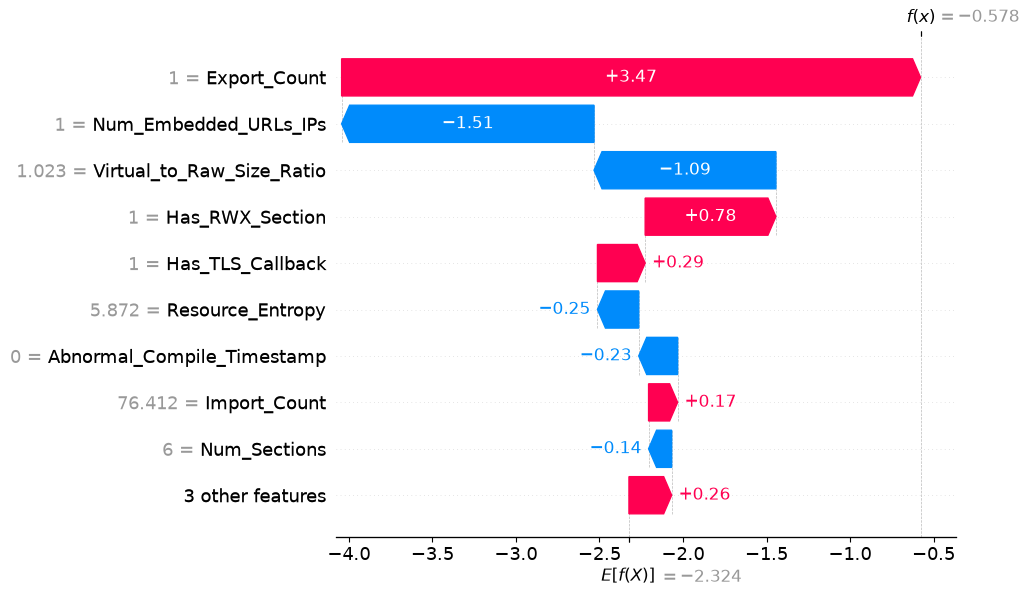

In [ ]:
# Fitted LightGBM pipeline
tree_model = fitted_models["LightGBM"]
tree_classifier = tree_model.named_steps["classifier"]

# Preserve feature names after preprocessing
X_test_transformed = pd.DataFrame(
    tree_model[:-1].transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Explain the fitted tree model
explainer = shap.TreeExplainer(tree_classifier)
shap_values = explainer(X_test_transformed)

shap.plots.beeswarm(shap_values)

# Find a case where Logistic Regression and LightGBM disagree
lr_prob = fitted_models["Logistic Regression"].predict_proba(X_test)[:, 1]
tree_prob = tree_model.predict_proba(X_test)[:, 1]

idx = np.where((lr_prob >= 0.5) != (tree_prob >= 0.5))[0][0]

shap.plots.waterfall(shap_values[idx])

## 4. SOC cost model and threshold selection

For the AtlasPay scenario, the SOC supplies these *illustrative planning assumptions* (not measured company costs):

- False positive (FP): $25 per alert (analyst investigation and workflow friction).
- False negative (FN): $500 per missed malicious file (expected response/remediation cost).
- A future inline-blocking scenario may raise FP cost to $2,000 because blocking a legitimate vendor update or payment-support executable could interrupt operations.


$$C(\tau)=25\,FP(\tau)+500\,FN(\tau)$$

The objective is to minimize the SOC's expected cost while balancing false positives and false negatives.

In [134]:
COST_FP = 25
COST_FN = 500

The cost of missing malware is 20 times higher than the cost of investigating a false alert. This means the optimal threshold will generally be lower than 0.5, because the SOC has a strong incentive to catch malware.

### 4.1 Generate out-of-fold (OOF) probabilities

OOF predictions allow us to estimate how the model performs on unseen development observations.

For each fold:
1. Train the model on the other folds.
2. Predict malware probabilities on the held-out fold.
3. Repeat until every development observation has an OOF prediction.

This prevents us from optimizing the threshold using predictions on data the model was trained on.

In [137]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

oof_probabilities = {}

for name, model in fitted_models.items():
    oof_probabilities[name] = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=1
    )[:, 1]

### 4.2 Find the cost-minimizing threshold

In [138]:
def find_best_threshold(y_true, probabilities, cost_fp, cost_fn):
    thresholds = np.unique(np.r_[0, probabilities, 1])

    results = []

    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        fp = np.sum((np.asarray(y_true) == 0) & (predictions == 1))
        fn = np.sum((np.asarray(y_true) == 1) & (predictions == 0))

        cost = cost_fp * fp + cost_fn * fn

        results.append({
            "Threshold": threshold,
            "FP": fp,
            "FN": fn,
            "Cost": cost
        })

    return pd.DataFrame(results).sort_values("Cost").iloc[0]

In [139]:
best_thresholds = {}

for name, probabilities in oof_probabilities.items():
    best = find_best_threshold(
        y_train,
        probabilities,
        COST_FP,
        COST_FN
    )

    best_thresholds[name] = best["Threshold"]

    print(f"\n{name}")
    print(best)


Logistic Regression
Threshold        0.287262
FP              49.000000
FN             142.000000
Cost         72225.000000
Name: 3605, dtype: float64

Stacking
Threshold        0.067305
FP             148.000000
FN             137.000000
Cost         72200.000000
Name: 3501, dtype: float64

LightGBM
Threshold        0.055131
FP             207.000000
FN             136.000000
Cost         73175.000000
Name: 3441, dtype: float64


### 4.3 Freeze thresholds and evaluate on the test set

In [140]:
test_results = []

for name, threshold in best_thresholds.items():
    probabilities = fitted_models[name].predict_proba(X_test)[:, 1]
    predictions = (probabilities >= threshold).astype(int)

    y_true = np.asarray(y_test)

    fp = np.sum((y_true == 0) & (predictions == 1))
    fn = np.sum((y_true == 1) & (predictions == 0))

    test_results.append({
        "Model": name,
        "Threshold": threshold,
        "FP": fp,
        "FN": fn,
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "Cost": COST_FP * fp + COST_FN * fn,
        "Alerts": np.sum(predictions == 1)
    })

test_results_df = pd.DataFrame(test_results)
display(test_results_df)

,Model,Threshold,FP,FN,Precision,Recall,Cost,Alerts
0,Logistic Regression,0.287262,10,34,0.966443,0.894410,17250,298
1,Stacking,0.067305,28,33,0.911672,0.897516,17200,317
2,LightGBM,0.055131,68,31,0.810585,0.903727,17200,359


### 4.4 Repeat with a higher false-positive cost of $2,000

In [141]:
COST_FP_BLOCK = 2000

blocking_thresholds = {}

for name, probabilities in oof_probabilities.items():
    best = find_best_threshold(
        y_train,
        probabilities,
        COST_FP_BLOCK,
        COST_FN
    )

    blocking_thresholds[name] = best["Threshold"]

    print(f"\n{name}")
    print(best)


Logistic Regression
Threshold         0.501573
FP               39.000000
FN              149.000000
Cost         152500.000000
Name: 3622, dtype: float64

Stacking
Threshold         0.721916
FP               40.000000
FN              146.000000
Cost         153000.000000
Name: 3618, dtype: float64

LightGBM
Threshold         0.740588
FP               41.000000
FN              153.000000
Cost         158500.000000
Name: 3624, dtype: float64


In [142]:
blocking_results = []

for name, threshold in blocking_thresholds.items():
    probabilities = fitted_models[name].predict_proba(X_test)[:, 1]
    predictions = (probabilities >= threshold).astype(int)

    y_true = np.asarray(y_test)

    fp = np.sum((y_true == 0) & (predictions == 1))
    fn = np.sum((y_true == 1) & (predictions == 0))

    blocking_results.append({
        "Model": name,
        "Threshold": threshold,
        "FP": fp,
        "FN": fn,
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "Cost": COST_FP_BLOCK * fp + COST_FN * fn,
        "Alerts": np.sum(predictions == 1)
    })

blocking_results_df = pd.DataFrame(blocking_results)
display(blocking_results_df)

,Model,Threshold,FP,FN,Precision,Recall,Cost,Alerts
0,Logistic Regression,0.501573,8,36,0.972789,0.888199,34000,294
1,Stacking,0.721916,8,37,0.972696,0.885093,34500,293
2,LightGBM,0.740588,8,41,0.972318,0.872671,36500,289


With an FP cost of $25, the SOC can tolerate more alerts because missing malware costs much more.

With an FP cost of $2,000, false alerts become much more expensive. The model therefore needs stronger evidence before flagging or blocking a file.

- Higher relative FN cost → lower threshold → more detections, but more false positives.
- Higher relative FP cost → higher threshold → fewer false positives, but potentially more missed malware.

### 4.5 Limitations of cost assumptions and dataset prevalence

#### Cost assumptions
In practice, these costs depend on several factors:
- False positives: Investigation time, analyst workload, alert fatigue and potential disruption to legitimate business operations.
- False negatives: Incident response, malware containment, data recovery, financial losses and potential reputational damage.
- Inline blocking: Blocking a legitimate executable, such as a vendor update or payment-support application, could interrupt critical business operations and create additional costs.

Assigning a fixed cost to every FP or FN oversimplifies reality. The impact of missing malware depends on its severity, capabilities and potential consequences, while investigation costs vary depending on alert complexity. Therefore, the selected thresholds are optimal only under the assumed cost structure. Different operational costs could produce different optimal thresholds.

#### Dataset prevalence
The dataset's malware prevalence may not represent the actual proportion of malicious files encountered in AtlasPay's environment.
A dataset can contain a much higher proportion of malicious samples than a real enterprise environment, where legitimate executables are generally much more common.
This matters because prevalence directly affects the expected number of false alerts, precision and overall operational workload.
Consequently, even if the model achieves strong precision and recall on the test set, its performance may differ significantly when deployed in a real SOC environment.

#### Capacity check: 120 alerts/day

Looking at test-set alert counts at the frozen thresholds, all three models produce more than 120 alerts in the test sample. However, these counts cannot be interpreted as daily alert forecasts because the test set represents a fixed sample rather than one day of AtlasPay telemetry.

A meaningful capacity assessment would require:
1. Real telemetry: The number of executable files scanned per day.
2. Representative prevalence: The actual proportion of malicious and legitimate files in the deployment environment.
3. Probability calibration: Verify that predicted probabilities correspond to observed malware frequencies using representative validation data.
4. Operational monitoring: Measure actual daily alert volume, false-positive rates, missed detections and analyst workload after deployment.

The model would then need to be evaluated on representative operational data to determine whether its alert volume remains within the 120-alert/day capacity.

---

## Final Architecture Decision: CISO Recommendation

### Executive recommendation

AtlasPay requires a malware detection solution capable of identifying malicious Windows PE executables before they enter or execute. The objective is to prioritize suspicious files for investigation while minimizing missed threats and unnecessary disruption to legitimate business operations.

- The positive class `Is_Malware = 1`. 
- The initial deployment should be analyst-assisted rather than autonomous because model predictions are not definitive proof of malicious activity. 
- False positives could affect legitimate vendor updates or payment-support executables
- False negatives could allow malware into the environment.
- Human review provides an additional verification layer before remediation or blocking decisions.

### Recommended model and operating threshold

For the initial perimeter-scanning scenario, I recommend **Logistic Regression with a threshold of 0.2873**, selected using out-of-fold development predictions under the illustrative costs of $25 per false positive and $500 per false negative.

The model achieved a test-set PR-AUC of 0.90799 during model comparison and, at the selected threshold, produced:

- Precision: **96.64%**
- Recall: **89.44%**
- False positives: **10**
- False negatives: **34**
- Total illustrative cost: **$17,250**
- Test-set alerts: **298**

Stacking achieved a slightly higher validation PR-AUC (0.91080) and a marginally lower test-set cost ($17,200), with 28 false positives and 33 false negatives. LightGBM also achieved a test-set cost of $17,200, but generated 68 false positives. The differences in cost are negligible relative to the overall illustrative costs.

Logistic Regression is preferable operationally because its inference latency was approximately 2.62 ms per 1,000 files, compared with 7.47 ms for LightGBM and 86.81 ms for Stacking. It also offers a simpler model structure and more straightforward interpretation through its coefficients and feature contributions.

Although Stacking achieved the highest validation PR-AUC (0.91080 versus 0.90799), its improvement is small and comes with substantially higher inference latency and model complexity. Logistic Regression therefore provides the more practical balance for the initial deployment.

### Capacity and inline-blocking considerations

The test-set alert count for Logistic Regression was 298, exceeding the scenario's 120-alert/day planning target. However, this comparison is indicative only: the test set is a sample, not a representative day of AtlasPay telemetry. A reliable daily forecast requires actual daily executable volumes, representative malware prevalence, endpoint and server telemetry, and calibrated probabilities evaluated against real operational data.

For inline blocking, the false-positive cost increases to $2,000. Under this alternative assumption, the development-selected Logistic Regression threshold rises to 0.5016. Its test results are 8 false positives, 36 false negatives, 97.28% precision, 88.82% recall and an illustrative cost of $34,000. Although Logistic Regression again has the lowest observed cost among the candidates, autonomous blocking should not yet be enabled. Legitimate payment-support operations could be interrupted, and the model has not been validated sufficiently in a real environment. Blocking should initially require analyst approval or additional independent verification.

### Production risks and required safeguards

Several risks must be addressed before production deployment:

- **The gap between synthetic and real data:** Dataset characteristics and labels may not represent real enterprise malware accurately. Validation on independently collected and verified PE samples is necessary.
- **Prevalence shift:** Real environments may contain a substantially smaller proportion of malware, reducing precision and changing alert volume.
- **Probability calibration:** Predicted scores must be calibrated and checked against observed malware frequencies before being interpreted as reliable risk estimates.
- **Data drift:** Changes in legitimate software, operating systems and malware families can reduce model performance. Continuous monitoring and periodic retraining are required.
- **Adversarial adaptation:** Attackers may modify executable characteristics to evade detection. The model should be complemented by signature-based detection, sandbox analysis and other security controls.
- **Analyst workflow:** Alerts should include risk scores, relevant feature explanations, file identifiers and investigation status to support efficient triage.
- **Monitoring and governance:** Track precision, recall, false-positive rates, missed detections, alert volume, latency and analyst feedback. Thresholds and model versions should be managed through a controlled review process.

### Final decision

Deploy **Logistic Regression as an analyst-assisted malware scanner**, initially using the frozen 0.2873 threshold under the supplied alerting cost assumptions. Treat the model as a prioritization and detection layer within a defense architecture, not as an independent security authority. Reassess the threshold and model choice after collecting representative AtlasPay telemetry and validating performance under real operational conditions. Autonomous blocking should remain a later-stage option, subject to stronger validation and safeguards.